# learned action scoring: Methods and evidence

**Level:** 2 **Prerequisites:** Learned action policies level 1 **Reading time:** 25 minutes

**Question:** How do the released M03 and M04 policies rank admissible actions when rerun on the C05 case?

## Objectives

This lesson investigates the question: How do the released M03 and M04 policies rank admissible actions when rerun on the C05 case?

## Setup

The versions below are pinned in `notebooks/requirements.txt` and are also recorded in this notebook's metadata;

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```

In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Data
The notebook reads committed product artifacts. Owner: Neuraxis. Repository: https://github.com/fsantibanezleal/CAOS_Neuraxis. License: Apache-2.0. The JSON is a first-party, frozen experiment artifact; no external benchmark data are redistributed in this notebook;

This notebook reads `data/derived/index.json` and the listed trace artifacts. The method run uses an isolated Reflexmesh case workspace; For learned methods, fetch the exact public release assets with `python -m reflexmesh; Cli fetch-models --destination models/checkpoints --version v0; 01.000`, then set `NEURAXIS_CHECKPOINTS` to that folder; The release manifest verifies asset hashes. Planner methods M09/M10 are read from frozen traces unless `NEURAXIS_NOTEBOOK_MODEL` explicitly names a configured local Ollama model;

Artifacts for this lesson:

- `data/derived/index.json` - `data/derived/benchmark-adequacy.json` - `data/derived/episodes/M03-C05-nominal-40000; - `data/derived/episodes/M04-C05-nominal-40000;json`

## Method

A candidate scorer maps each admissible candidate's features to a preference; calibration changes the interpretation of scores but does not establish causal benefit. The M03 logistic model and M04 boosted-tree model inherit the training distribution, label construction and held-out split. Their action output is still checked against the current admissible set before execution. This distinction matters when one candidate has a high predicted probability but an expired resource revision or missing capability. The example uses a single frozen C05 observation to make the feature-to-choice path inspectable. Its result cannot measure calibration quality; that requires the held-out calibration records and a reliability analysis across independent groups. In the reproducibility check for learned action scoring on C05, A fitted classifier estimates preference from features and labels, whereas the admissibility mask remains a runtime safety constraint; In the reproducibility check for learned action scoring on C05, probability calibration and legal action selection are separate measurable properties. Within this learned action scoring rerun (C05), the C05 replay is useful for tracing feature construction and score ranking, but a learner can memorize task identifiers unless split design withholds relevant compositions and reports the held-out denominator. For this level, inspect the candidate features and the learned score together, then verify that the chosen action was admissible before attributing the outcome to model quality.

### learned action scoring · level 2 | Verify the audit and each trace's bytes before interpreting outcomes.

In [2]:
# Load and hash-check the selected first-party traces; never edit the canonical artifacts.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M03", "M04"]
trace_methods = ["M03", "M04"]
sample_case = "C05"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Hash-verified trace records:", len(records))


Hash-verified trace records: 2


### learned action scoring · level 2 | Execute the released policies and compare the run

### learned action scoring · level 2 | Compare the full sequence, not only the first action

### learned action scoring · L2 | Build the first executable policy

In level 2, construct policy M03 for learned action scoring with the public factory and keep its observation contract unchanged before sampling C05.

In [3]:
# Construct the first released policy through the public factory.
primary_id = "M03"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M03


### learned action scoring · L2 | Execute the primary method on the named case

In the reproducibility check for learned action scoring on C05, the learned action scoring evaluator runs M03 on C05 and derives success from the independent task postcondition, not from a replayed trace.

In [4]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### learned action scoring · L2 | Construct an independent comparison policy

Within this learned action scoring rerun (C05), create M04 as a fresh object so recurrent state from M03 cannot leak into the matched comparison.

In [5]:
# Create a fresh policy object for the matched comparison.
secondary_id = "M04"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M04


### learned action scoring · L2 | Run the comparison under identical conditions

This level 2 comparison runs M04 on the same C05, nominal variant and seed, and it illustrates behavior rather than estimating a population rate.

In [6]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### learned action scoring · L2 | Aggregate the two executed episodes

In the reproducibility check for learned action scoring on C05, the package aggregator summarizes two executed learned action scoring episodes, and cross-family claims still require the complete benchmark below.

In [7]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### learned action scoring · L2 | Fresh policy outcomes

Within this learned action scoring rerun (C05), the next plot is computed from the learned action scoring episode results just executed for C05 rather than copied from a frozen artifact.

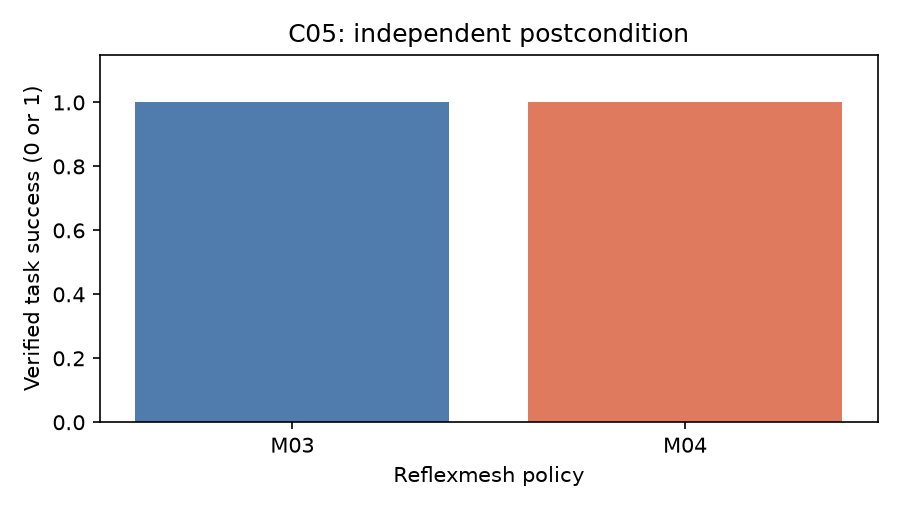

In [8]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Verified task success (0 or 1)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: independent postcondition")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Within this learned action scoring rerun (C05), for learned action scoring, these bars show fresh task-postcondition outcomes for M03 and M04 on C05, with success encoded as 1 and failure as 0. Read the case and seed before comparing them. In the reproducibility check for learned action scoring on C05, this controlled episode illustrates policy behavior but is not a confidence interval and does not establish generalization to other software tasks;

### learned action scoring · L2 | Recorded controller time

Within this learned action scoring rerun (C05), the learned action scoring timing chart uses hash-verified frozen records for M03 and M04 on C05, not machine-dependent timings from fresh episodes. This level 2 learned action scoring view describes the recorded environment under its declared case, variant and seed.

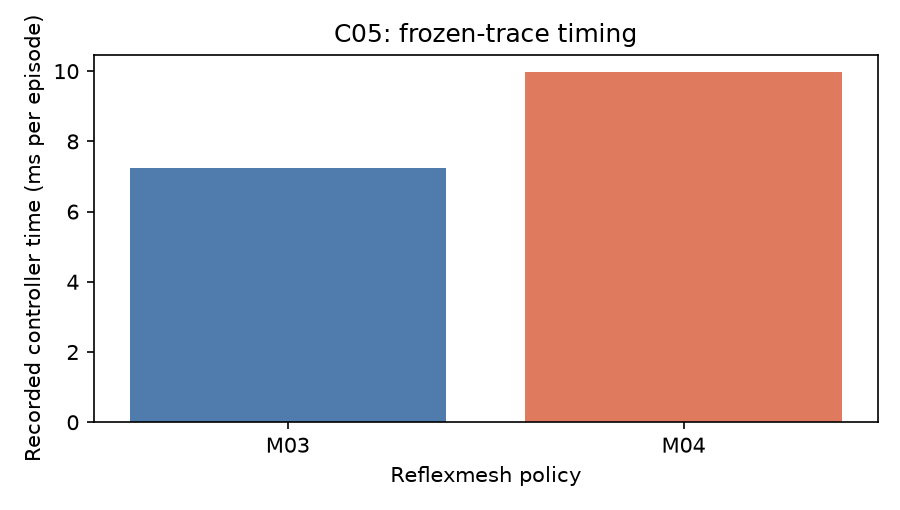

In [9]:
# Plot controller time from the hash-verified frozen records for the matched methods.
labels = list(fresh_runs)
latencies = [records[name]["metrics"]["controller_ms"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Recorded controller time (ms per episode)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: frozen-trace timing")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


The level 2 learned action scoring chart reads canonical M03/M04 records for C05, nominal variant and seed 40000 after the data boundary verifies their hashes. For the matched learned action scoring rerun on C05, for this learned action scoring lesson, the stable figure describes recorded latency and intentionally makes no current-machine speed claim.

## Results

**Answer:** The learned action scoring comparison executes 2 fresh policy episodes, M03 and M04, under identical C05 conditions; keep the learned action scoring family and seed strata in view because the frozen matrix contains designed, not population-sampled, tasks.

In the reproducibility check for learned action scoring on C05, the package checkpoints are separately released assets and are not committed The displayed fitted-method outcomes are the hash-verified recorded evaluations, not a freshly refitted model; In the reproducibility check for learned action scoring on C05, A rate on designed families is not an estimate for arbitrary software tasks;

## Summary

For the matched learned action scoring rerun on C05, this learned action scoring example uses C05 to show behavior under one declared condition. For the matched learned action scoring rerun on C05, keep the measured outcome separate from claims about broader software-control intelligence.



## References
- [XGB](https://arxiv.org/abs/1603.02754) - [GRU](https://arxiv.org/abs/1406.1078) - [LINUCB](https://arxiv.org/abs/1003.0146)